# Assignment 1 — GCN from scratch
Dataset → splits → GCN steps → training → correctness checks → MLP comparison → edge ablation.

In [1]:
import sys; sys.path.append("../src")
import torch, numpy as np, pandas as pd
from data import make_graph, make_splits, edge_homophily
from models import GCN, MLP, add_self_loops, gcn_norm
from train import train, accuracy
from checks import manual_layer_check, permutation_check, ablation, random_edges, eval_with_edges
import viz

SEED = 0
torch.manual_seed(SEED)

## 1. Dataset design
* **Labels:** 200 nodes, 2 balanced classes, randomly assigned.
* **Features (3):** class mean + Gaussian noise. Means differ only slightly, so classes overlap heavily; feature 3 is pure noise. Labels are *not* a feature.
* **Edges:** stochastic block model — same-class pairs connect with p=0.08, different-class with p=0.01. Neighbours therefore carry label information that a single node's features lack.

nodes: 200 | features: 3 | undirected edges: 929
edge homophily: 0.888 (0.5 = random)


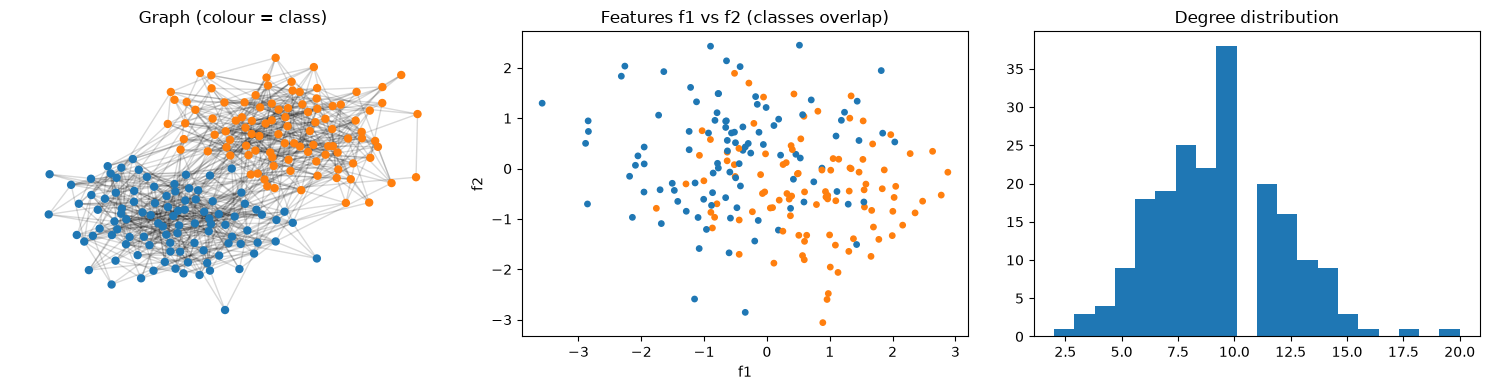

In [2]:
x, y, edge_index = make_graph(n=200, seed=SEED)
print("nodes:", x.size(0), "| features:", x.size(1), "| undirected edges:", edge_index.size(1)//2)
print("edge homophily:", round(edge_homophily(edge_index, y), 3), "(0.5 = random)")
viz.plot_dataset(x, y, edge_index)

## 2. Train / validation / test split (labels never enter the input features)

train/val/test: 60 40 100


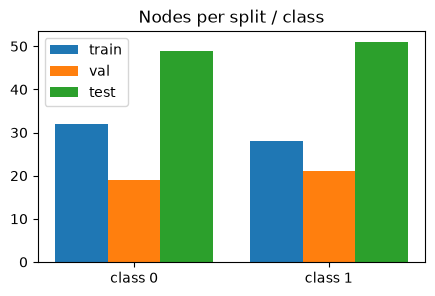

In [3]:
masks = make_splits(x.size(0), seed=SEED)
tr, va, te = masks
print("train/val/test:", tr.sum().item(), va.sum().item(), te.sum().item())
assert not (tr & va).any() and not (tr & te).any() and not (va & te).any()   # disjoint
assert x.shape[1] == 3                                                        # only the 3 features
viz.plot_splits(y, masks)

## 3. GCN steps: self-loops → degree normalisation → message passing

edges before / after self-loops: 1858 / 2058
first 5 edge weights 1/sqrt(d_i d_j): tensor([0.0714, 0.0772, 0.0741, 0.0945, 0.1010])


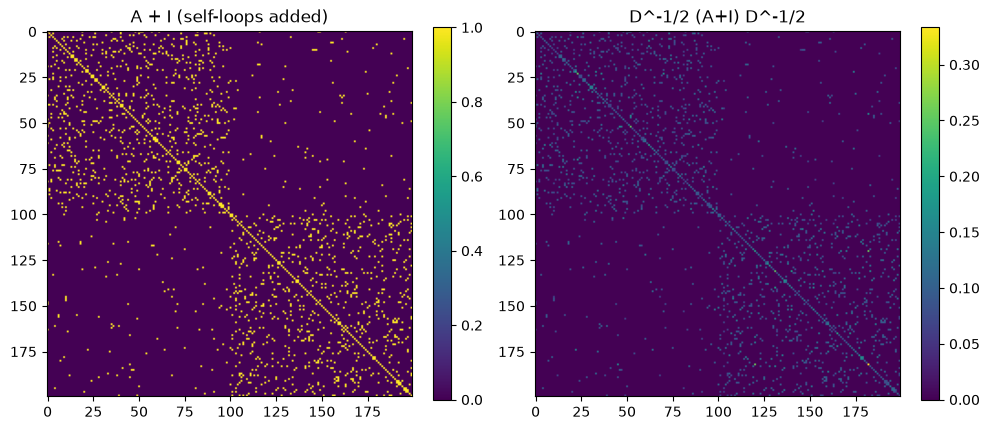

In [4]:
n = x.size(0)
ei_sl = add_self_loops(edge_index, n)
w = gcn_norm(ei_sl, n)
print("edges before / after self-loops:", edge_index.size(1), "/", ei_sl.size(1))
print("first 5 edge weights 1/sqrt(d_i d_j):", w[:5])
viz.plot_adjacency(edge_index, y)

## 4. Train the 2-layer GCN

best val acc: 1.000 | test acc: 0.990


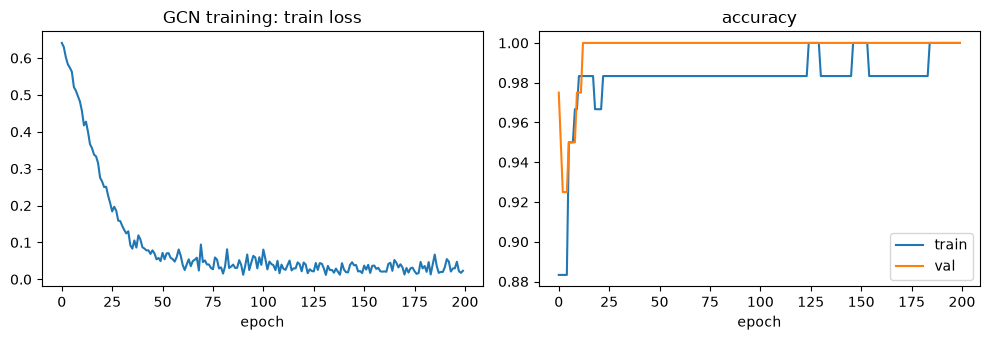

In [5]:
model = GCN(3, 16, 2)
hist, best_val, gcn_test = train(model, x, edge_index, y, masks)
print(f"best val acc: {best_val:.3f} | test acc: {gcn_test:.3f}")
viz.plot_curves(hist)

## 5. Check 1 — one node, one layer, manual calculation

In [6]:
r = manual_layer_check(model, x, edge_index)
print("node:", r["node"], "| neighbours incl. self:", r["neighbours"])
print("layer output :", r["auto"])
print("manual calc  :", r["manual"])
print("MATCH:", r["match"])
assert r["match"]

node: 0 | neighbours incl. self: [40, 57, 66, 101, 106, 107, 116, 117, 122, 148, 149, 163, 166, 0]
layer output : tensor([-0.2303, -0.3028,  0.5723,  0.4965,  0.3811, -0.1715, -0.0064, -0.3187,
         0.2516, -0.1807, -0.0276, -0.0209,  0.1539,  0.4397,  0.4865,  0.2949])
manual calc  : tensor([-0.2303, -0.3028,  0.5723,  0.4965,  0.3811, -0.1715, -0.0064, -0.3187,
         0.2516, -0.1807, -0.0276, -0.0209,  0.1539,  0.4397,  0.4865,  0.2949])
MATCH: True


## 6. Check 2 — permutation equivariance (relabel nodes + shuffle edge order)

In [7]:
ok, err = permutation_check(model, x, edge_index)
print("equivariant:", ok, "| max abs difference:", err)
assert ok

equivariant: True | max abs difference: 1.7881393432617188e-07


## 7. GCN vs MLP vs broken graph (5 seeds, same features and split)

,mean,std
MLP (no edges),0.786,0.024
GCN (real edges),0.986,0.005
GCN (random edges),0.674,0.045
GCN (self-loops only),0.792,0.016


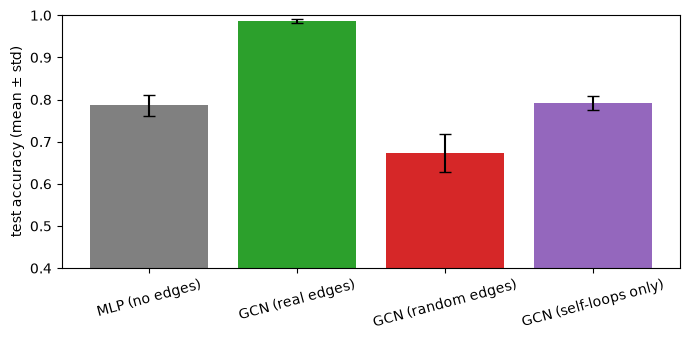

In [8]:
res = ablation(x, y, edge_index, masks, seeds=range(5))
df = pd.DataFrame({k: [np.mean(v), np.std(v)] for k, v in res.items()}, index=["mean", "std"]).T
display(df.round(3))
viz.plot_ablation(res)

### Same trained GCN, edges swapped only at test time

In [9]:
rand_ei = random_edges(edge_index, n)
print("trained GCN, real edges  :", round(eval_with_edges(model, x, edge_index, y, te), 3))
print("trained GCN, random edges:", round(eval_with_edges(model, x, rand_ei, y, te), 3))
print("trained GCN, no edges    :", round(eval_with_edges(model, x, torch.empty(2,0,dtype=torch.long), y, te), 3))

trained GCN, real edges  : 0.99
trained GCN, random edges: 0.69
trained GCN, no edges    : 0.78


## 8. Does the model use the graph? (embeddings)

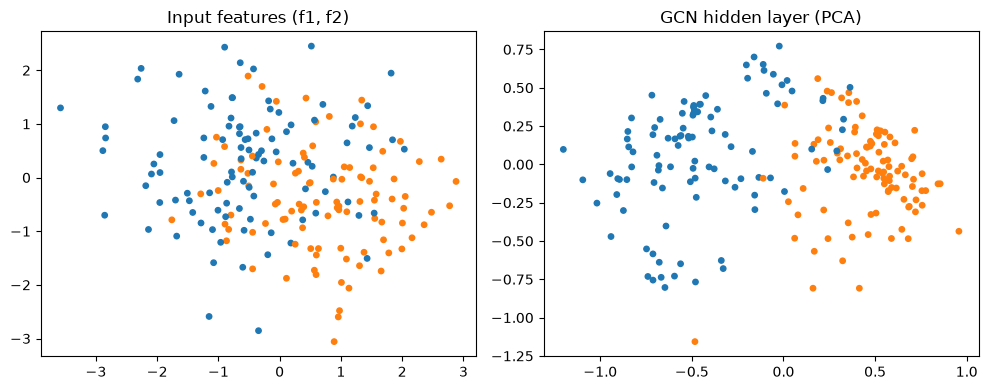

In [10]:
viz.plot_embeddings(model, x, edge_index, y)

#### Conclusions
The model uses the graph structure, and it helps a lot. With the same features, the same split and the same hidden size, the GCN gains about 20 percentage points over the MLP. The gap is far larger than the seed-to-seed spread, so it is not noise.

The gain comes from the connections themselves, not from the GCN architecture. Keeping the model but giving it random edges loses the whole advantage and falls below the MLP. Same code, same parameters, different edges: that is the controlled comparison the assignment asks for.

A GCN without informative edges behaves like an MLP. The self-loops-only GCN (no neighbours) lands at the MLP’s level. This also acts as a sanity check on your implementation: with no neighbours, message passing does nothing and the model should match the plain MLP.

Wrong edges are worse than no edges. Random edges bring in features from nodes of both classes, so each node’s representation is polluted. That also explains why the std is largest for this bar: the result depends on which random edges happened to be drawn.
## 9. Conclusions (fill in with your numbers)
* GCN vs MLP: …
* Random / removed edges drop GCN toward MLP level → the model uses structure: …
* Both correctness checks pass: …

In [11]:
!pytest ../tests/test_assignment1.py -q

...............                                                          [100%]
15 passed in 29.09s
